# ENSO station table builder

This notebook combines daily observations from nine primary weather stations with the prepared ONI, RONI and TNI records to build seasonal weather comparison tables.

Prepared inputs:
- ../station_data/ghcnd/record_splices/all_station_data_spliced.csv
- ../indicies_data/first_pass/enso_historical_indicies.csv

RONI is the project's primary index, ONI is secondary, and TNI is retained as provided. Monthly date keys align the index records with station observations. Weather quality flags are applied before calculating the weather metrics.

The daily merged output is saved to ../outputs/station_obs_enso_indicies.csv in the input units. Final weather tables use Fahrenheit and inches.

v1.1 includes:
- DJF, MAM, JJA and SON throughout the analysis.
- Separate El Niño, La Niña, neutral and unknown outcomes.
- Results from 1950 onward while preserving full historical inputs.
- Missing-data reporting, contributing sample counts and SD.
- An exact saved Kenny reference table, followed by individual-station and agreed ensemble tables. Kenny's variables, time windows and layout will be confirmed before reproduction.

Station ensembles summarize the selected stations using explicitly defined membership and weighting.

Workflow: index download->station download -> data splice -> table builder

In [29]:
import pandas as pd
from pathlib import Path
import nbformat
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [30]:
# uncomment and run this cell to prepare all data
# %run enso_indicies_download_v1.1.ipynb
# %run ghcnd_station_download_v1.1.ipynb
# %run data_splice.ipynb

## Preprocessing
The code below make a raw data table that combines station data and ENSO indicies data.  
It also filters out rows with no observations. 

In [31]:
#assign data to vars for pandas
indicies_data=Path('../indicies_data/first_pass/enso_historical_indicies.csv')
station_data = Path("../station_data/ghcnd/record_splices/all_station_data_spliced.csv")

#read data into the dataframe

#used for run identification 
indicies_data_df_forfunction=pd.read_csv(indicies_data, skiprows=0,parse_dates=['Date']
                                                        )
#el nino index vals
indicies_data_df=pd.read_csv(
    indicies_data,
    skiprows=0,
    parse_dates=['Date']
)

#read station values while preserving flags and observation-time text
station_columns = pd.read_csv(station_data, nrows=0).columns
station_types = {
    "station": "string",
    "name": "string",
    "lat": "float64",
    "lon": "float64",
    "winter_year": "int64",
}
for column in station_columns:
    if column.endswith(("_qflag", "_mflag", "_sflag", "_obs_time")):
        station_types[column] = "string"
    elif column.endswith("_q"):
        station_types[column] = "boolean"
        station_types[column.removesuffix("_q")] = "float32"

stations_data_df = pd.read_csv(
    station_data,
    dtype=station_types,
    parse_dates=["time"],
    keep_default_na=False,
    na_values=[""],
    low_memory=False,
)

if stations_data_df[["station", "time"]].isna().any().any():
    raise ValueError("Station-day keys contain missing values.")
if stations_data_df.duplicated(["station", "time"]).any():
    raise ValueError("Station data contains duplicate station-days.")

#discard rows with no obs
stations_data_df=stations_data_df.dropna(
    subset=["TMAX", "TMIN", "PRCP", "MDPR", "DAPR",
               "SNOW", "MDSF", "DASF", "SNWD", "WESD", "WESF"],
    how='all'
)

In [32]:
#create a key they can be joined on
indicies_data_df['Month']=indicies_data_df['Date'].dt.to_period('M')
stations_data_df['Month']=stations_data_df['time'].dt.to_period('M')

In [33]:
#join the tables by date

station_obs_enso_indicies= pd.merge(
    left=stations_data_df,
    right=indicies_data_df,
    on='Month',
    how='left',
    validate='many_to_one'
)

In [34]:
#daily table with raw values only
store_table=Path('../outputs')
store_table.mkdir(parents=True, exist_ok=True)
station_obs_enso_indicies.to_csv(store_table/'station_obs_enso_indicies.csv', index=False)
display(station_obs_enso_indicies)

,station,time,TMAX,TMAX_q,TMAX_qflag,TMAX_mflag,TMAX_sflag,TMAX_obs_time,TMIN,TMIN_q,...,lat,lon,name,winter_year,Month,Date,ONI,RONI,TNI,Year
0,USW00014926,1904-09-01,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1905,1904-09,1904-09-01,0.68,1.04,0.584,1904
1,USW00014926,1904-09-02,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1905,1904-09,1904-09-01,0.68,1.04,0.584,1904
2,USW00014926,1904-09-03,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1905,1904-09,1904-09-01,0.68,1.04,0.584,1904
3,USW00014926,1904-09-04,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1905,1904-09,1904-09-01,0.68,1.04,0.584,1904
4,USW00014926,1904-09-05,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1905,1904-09,1904-09-01,0.68,1.04,0.584,1904
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298952,USW00014920,2026-09-23,20.600000,False,<NA>,<NA>,1,<NA>,6.7,False,...,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2027,2026-09,2026-09-01,NaN,NaN,NaN,2026
298953,USW00014920,2026-09-24,21.100000,False,<NA>,<NA>,1,<NA>,9.4,False,...,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2027,2026-09,2026-09-01,NaN,NaN,NaN,2026
298954,USW00014920,2026-09-25,22.799999,False,<NA>,<NA>,1,<NA>,15.0,False,...,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2027,2026-09,2026-09-01,NaN,NaN,NaN,2026
298955,USW00014920,2026-09-26,22.200001,False,<NA>,<NA>,1,<NA>,11.7,False,...,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2027,2026-09,2026-09-01,NaN,NaN,NaN,2026


## Processing

The code below makes the primary observation+index table for ENSO Proj Phase One


In [35]:
#continue with the merged table and preserve its column types
raw_table_df = station_obs_enso_indicies.copy(deep=True)

In [36]:
#label daily rows with their season and season year
month_to_season = {
    12: "DJF", 1: "DJF", 2: "DJF",
    3: "MAM", 4: "MAM", 5: "MAM",
    6: "JJA", 7: "JJA", 8: "JJA",
    9: "SON", 10: "SON", 11: "SON",
}

months = raw_table_df["time"].dt.month

raw_table_df["season"] = months.map(month_to_season)
raw_table_df["season_year"] = (
    raw_table_df["time"].dt.year
    + months.eq(12).astype("int64")
)

In [37]:
#helper functions to add and calculate columns


# Detect sustained warm or cold episodes and record their extreme value.
def identify_runs(df, index_column, index_df, phase="El Niño"):
    if phase not in ("El Niño", "La Niña"):
        raise ValueError("phase must be El Niño or La Niña")

    months = pd.to_datetime(df["time"]).dt.to_period("M")

    #detect episodes from the independent monthly index record
    index_series = pd.Series(
        index_df[index_column].to_numpy(),
        index=pd.PeriodIndex(pd.to_datetime(index_df["Date"]), freq="M"),
        name=index_column,
    )

    if index_series.empty or index_series.index.isna().any():
        raise ValueError(f"{index_column}: Missing or empty monthly dates.")
    if index_series.index.has_duplicates:
        raise ValueError(f"{index_column}: Duplicate monthly dates.")

    index_series = index_series.sort_index()
    index_series = index_series.reindex(
        pd.period_range(
            start=index_series.index.min(),
            end=index_series.index.max(),
            freq="M",
        )
    )
    
    index_series=index_series.round(1) #this corrects the descepancy between Brian Mcnoldy calcs and NOAAs publication
    
    qualifying = (
        index_series >= 0.5 if phase == "El Niño"
        else index_series <= -0.5
    )

    window_ends = (
        qualifying
        .rolling(window=5)
        .sum()
        .eq(5)
    )

    episode = (
        window_ends
        | window_ends.shift(-1, fill_value=False)
        | window_ends.shift(-2, fill_value=False)
        | window_ends.shift(-3, fill_value=False)
        | window_ends.shift(-4, fill_value=False)
    )

    # A new episode starts when False changes to True
    episode_start = (
        episode & ~episode.shift(1, fill_value=False)
    )

    # Number the episodes; leave non-episode positions missing
    episode_id = (
        episode_start.cumsum()
        .astype('Int64')
        .where(episode)
    )

    #Warm episodes use the maximum; cold episodes use the minimum.
    extreme = 'max' if phase == 'El Niño' else 'min'
    episode_peak = index_series.groupby(episode_id).transform(extreme)

        #check whether missing neighboring entries could complete an episode
    possible_months = pd.period_range(
        start=index_series.index.min() - 4,
        end=index_series.index.max() + 4,
        freq="M",
    )
    possible = (qualifying | index_series.isna()).reindex(
        possible_months, fill_value=True
    )
    possible_window_ends = possible.rolling(window=5).sum().eq(5)
    possible_episode = (
        possible_window_ends
        | possible_window_ends.shift(-1, fill_value=False)
        | possible_window_ends.shift(-2, fill_value=False)
        | possible_window_ends.shift(-3, fill_value=False)
        | possible_window_ends.shift(-4, fill_value=False)
    ).reindex(index_series.index)

    #keep confirmed episodes; mark missing or unresolved status as unknown
    unresolved = possible_episode & ~episode
    episode = episode.astype("boolean")
    episode = episode.mask(index_series.isna() | unresolved, pd.NA)

    return pd.DataFrame({
        'episode': months.map(episode),
        'episode_id': months.map(episode_id),
        'episode_peak': months.map(episode_peak)
    })


# Classify an individual value and/or or an episode's maximum/minimum
def oni_classify(value):
    if pd.isna(value):
        return pd.NA
    elif value >= 1.5:
        return 'Strong El Niño'
    elif 1.0 <= value <= 1.4:
        return 'Moderate El Niño'
    elif 0.5 <= value <= 0.9:
        return 'Weak El Niño'
    elif -0.5 < value < 0.5:
        return 'ENSO Neutral Phase'
    elif -0.9 <= value <= -0.5:
        return 'Weak La Niña'
    elif -1.4 <= value <= -1.0:
        return 'Moderate La Niña'
    elif value <= -1.5:
        return 'Strong La Niña'
    else:
        return 'Unclassified strength'


def roni_classify(value):
    if pd.isna(value):
        return pd.NA
    elif value >= 2.0:
        return 'Very Strong El Niño'
    elif value >= 1.5:
        return 'Strong El Niño'
    elif value >= 1.0:
        return 'Moderate El Niño'
    elif value >= 0.5:
        return 'Weak El Niño'
    elif value > -0.5:
        return 'ENSO Neutral Phase'
    elif value > -1.0:
        return 'Weak La Niña'
    elif value > -1.5:
        return 'Moderate La Niña'
    elif value > -2.0:
        return 'Strong La Niña'
    else:
        return 'Very Strong La Niña'


#makes a D of one year 
# and JF of the next share a winter year
def winter_year(date):
   if date.month==12:
       return date.year+1
   else:
       return date.year


#selects rows with el nino active
def identify_ninos(df, index):
    status = df[f'{index}_episode']
    return df[status.eq(True).fillna(False)]


#selects rows without el nino active
def indentify_non_ninos(df, index):
    status = df[f'{index}_episode']
    return df[status.eq(False).fillna(False)]

#classify phase while preserving nonpersistent and unresolved amplitudes
def classify_phase(values, warm_status, cold_status):
    values = values.round(1)
    warm = warm_status.astype("boolean")
    cold = cold_status.astype("boolean")
    observed = values.notna()
    phase = pd.Series("Unknown", index=values.index, dtype="string")

    phase.loc[observed & values.between(-0.5, 0.5, inclusive="neither")] = (
        "ENSO Neutral Phase"
    )

    #observed anomalies that cannot form a qualifying episode
    phase.loc[observed & values.ge(0.5) & warm.eq(False).fillna(False)] = (
        "Nonpersistent warm anomaly"
    )
    phase.loc[observed & values.le(-0.5) & cold.eq(False).fillna(False)] = (
        "Nonpersistent cold anomaly"
    )

    #observed anomalies whose episode status remains unresolved
    phase.loc[observed & values.ge(0.5) & warm.isna()] = (
        "Provisional warm anomaly"
    )
    phase.loc[observed & values.le(-0.5) & cold.isna()] = (
        "Provisional cold anomaly"
    )

    #confirmed warm and cold episodes
    phase.loc[observed & warm.eq(True).fillna(False)] = "El Niño"
    phase.loc[observed & cold.eq(True).fillna(False)] = "La Niña"
    return phase

In [38]:
#this makes the 'primary obs table' we ask our table questions in the next cell
#create columns and classify with helper functions

#calls helper function to find sst anomaly runs
oni_results = identify_runs(raw_table_df, 'ONI', indicies_data_df_forfunction)
roni_results = identify_runs(raw_table_df, 'RONI', indicies_data_df_forfunction)


#creates columns for values
raw_table_df['ONI_episode'] = oni_results['episode'] #true if rows index is part of a run
raw_table_df['ONI_episode_id'] = oni_results['episode_id'] #unique id per yearly event
raw_table_df['ONI_episode_peak'] = oni_results['episode_peak'] #documents the highest value 


raw_table_df['RONI_episode'] = roni_results['episode'] #all three of these 
raw_table_df['RONI_episode_id'] = roni_results['episode_id'] #have the same defintions
raw_table_df['RONI_episode_peak'] = roni_results['episode_peak'] #as the oni


#calls helper function to evaluate the peak
raw_table_df['ONI_episode_strength'] = (
    raw_table_df['ONI_episode_peak'].apply(oni_classify) #assings strong very strong etc
)

raw_table_df['RONI_episode_strength'] = (
    raw_table_df['RONI_episode_peak'].apply(roni_classify) #same as above
)


#calls helper function
#classify individual three month values including neutral conditions
#does not evaluate persistence so these arent el ninos individually
raw_table_df['ONI_monthly_class'] = raw_table_df['ONI'].round(1).apply(oni_classify)
raw_table_df['RONI_monthly_class'] = raw_table_df['RONI'].round(1).apply(roni_classify)

#currently redundant
#detect and classify la nina episodes independently of el nino episodes
for index, classify in [('ONI', oni_classify), ('RONI', roni_classify)]:
    cold_results = identify_runs(
    raw_table_df, index, indicies_data_df_forfunction, phase="La Niña"
    )
    raw_table_df[f'{index}_la_nina_episode'] = cold_results['episode']
    raw_table_df[f'{index}_la_nina_episode_id'] = cold_results['episode_id']
    raw_table_df[f'{index}_la_nina_episode_peak'] = cold_results['episode_peak']
    raw_table_df[f'{index}_la_nina_episode_strength'] = (
        cold_results['episode_peak'].apply(classify)
    )

#add distinct phase labels for both indices
for index in ["ONI", "RONI"]:
    raw_table_df[f"{index}_phase"] = classify_phase(
        raw_table_df[index],
        raw_table_df[f"{index}_episode"],
        raw_table_df[f"{index}_la_nina_episode"],
    )
    
#uncomment to check out the new columns
display(raw_table_df.iloc[:, :20])
display(raw_table_df.iloc[:, :40])


,station,time,TMAX,TMAX_q,TMAX_qflag,TMAX_mflag,TMAX_sflag,TMAX_obs_time,TMIN,TMIN_q,TMIN_qflag,TMIN_mflag,TMIN_sflag,TMIN_obs_time,PRCP,PRCP_q,PRCP_qflag,PRCP_mflag,PRCP_sflag,PRCP_obs_time
0,USW00014926,1904-09-01,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,0.000000,False,<NA>,P,6,<NA>
1,USW00014926,1904-09-02,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,41.400002,False,<NA>,<NA>,6,<NA>
2,USW00014926,1904-09-03,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,48.500000,False,<NA>,<NA>,6,<NA>
3,USW00014926,1904-09-04,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,0.000000,False,<NA>,P,6,<NA>
4,USW00014926,1904-09-05,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,0.000000,False,<NA>,P,6,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298952,USW00014920,2026-09-23,20.600000,False,<NA>,<NA>,1,<NA>,6.7,False,<NA>,<NA>,1,<NA>,0.000000,False,<NA>,<NA>,1,2400
298953,USW00014920,2026-09-24,21.100000,False,<NA>,<NA>,1,<NA>,9.4,False,<NA>,<NA>,1,<NA>,0.300000,False,<NA>,<NA>,1,2400
298954,USW00014920,2026-09-25,22.799999,False,<NA>,<NA>,1,<NA>,15.0,False,<NA>,<NA>,1,<NA>,0.000000,False,<NA>,<NA>,1,2400
298955,USW00014920,2026-09-26,22.200001,False,<NA>,<NA>,1,<NA>,11.7,False,<NA>,<NA>,1,<NA>,0.000000,False,<NA>,<NA>,1,2400


,station,time,TMAX,TMAX_q,TMAX_qflag,TMAX_mflag,TMAX_sflag,TMAX_obs_time,TMIN,TMIN_q,...,DAPR_sflag,DAPR_obs_time,SNOW,SNOW_q,SNOW_qflag,SNOW_mflag,SNOW_sflag,SNOW_obs_time,MDSF,MDSF_q
0,USW00014926,1904-09-01,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False
1,USW00014926,1904-09-02,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False
2,USW00014926,1904-09-03,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False
3,USW00014926,1904-09-04,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False
4,USW00014926,1904-09-05,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False,...,<NA>,<NA>,NaN,False,<NA>,<NA>,<NA>,<NA>,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298952,USW00014920,2026-09-23,20.600000,False,<NA>,<NA>,1,<NA>,6.7,False,...,<NA>,<NA>,0.0,False,<NA>,<NA>,1,<NA>,NaN,False
298953,USW00014920,2026-09-24,21.100000,False,<NA>,<NA>,1,<NA>,9.4,False,...,<NA>,<NA>,0.0,False,<NA>,<NA>,1,<NA>,NaN,False
298954,USW00014920,2026-09-25,22.799999,False,<NA>,<NA>,1,<NA>,15.0,False,...,<NA>,<NA>,0.0,False,<NA>,<NA>,1,<NA>,NaN,False
298955,USW00014920,2026-09-26,22.200001,False,<NA>,<NA>,1,<NA>,11.7,False,...,<NA>,<NA>,0.0,False,<NA>,<NA>,1,<NA>,NaN,False


In [39]:
#classify the full monthly index record independently of station coverage
monthly_index_table = (
    indicies_data_df_forfunction
    .rename(columns={"Date": "time"})
    .sort_values("time")
    .reset_index(drop=True)
    .copy()
)

for index, classify in [("ONI", oni_classify), ("RONI", roni_classify)]:
    warm = identify_runs(
        monthly_index_table, index, indicies_data_df_forfunction
    )
    cold = identify_runs(
        monthly_index_table, index, indicies_data_df_forfunction, phase="La Niña"
    )

    #retain separate warm and cold episode flags, IDs and peaks
    for field in ["episode", "episode_id", "episode_peak"]:
        monthly_index_table[f"{index}_{field}"] = warm[field]
        monthly_index_table[f"{index}_la_nina_{field}"] = cold[field]

    values = monthly_index_table[index].round(1)
    phase = classify_phase(values, warm["episode"], cold["episode"])
    monthly_index_table[f"{index}_rounded"] = values
    monthly_index_table[f"{index}_phase"] = phase

    #seasonal strength uses this centered entry for confirmed phases
    monthly_index_table[f"{index}_season_strength"] = (
        values.apply(classify).where(
            phase.isin(["El Niño", "La Niña", "ENSO Neutral Phase"]), pd.NA
        )
    )

    #retain full episode strength separately from seasonal strength
    monthly_index_table[f"{index}_episode_strength"] = (
        warm["episode_peak"].apply(classify)
    )
    monthly_index_table[f"{index}_la_nina_episode_strength"] = (
        cold["episode_peak"].apply(classify)
    )

In [40]:
#select one centered entry per season, then limit reported season years
center_to_season = {1: "DJF", 4: "MAM", 7: "JJA", 10: "SON"}

seasonal_index_table_full = monthly_index_table.loc[
    monthly_index_table["time"].dt.month.isin(center_to_season)
].copy()

seasonal_index_table_full["season"] = (
    seasonal_index_table_full["time"].dt.month.map(center_to_season)
)

seasonal_index_table_full["season_year"] = (
    seasonal_index_table_full["time"].dt.year
)

seasonal_index_table_full = seasonal_index_table_full.rename(
    columns={"time": "index_center"}
).reset_index(drop=True)

#keep full history above; use the selected period for analysis products
seasonal_index_table = seasonal_index_table_full.loc[
    seasonal_index_table_full["season_year"].ge(1950)
].copy().reset_index(drop=True)

#retain the different ONI and RONI strength definitions
print("Strength bins use rounded absolute index magnitudes:")
print("ONI: weak 0.5-<1.0; moderate 1.0-<1.5; strong >=1.5.")
print(
    "RONI: weak 0.5-<1.0; moderate 1.0-<1.5; "
    "strong 1.5-<2.0; very strong >=2.0."
)
display(seasonal_index_table)

Strength bins use rounded absolute index magnitudes:
ONI: weak 0.5-<1.0; moderate 1.0-<1.5; strong >=1.5.
RONI: weak 0.5-<1.0; moderate 1.0-<1.5; strong 1.5-<2.0; very strong >=2.0.


,index_center,ONI,RONI,TNI,Year,ONI_episode,ONI_la_nina_episode,ONI_episode_id,ONI_la_nina_episode_id,ONI_episode_peak,...,RONI_la_nina_episode_id,RONI_episode_peak,RONI_la_nina_episode_peak,RONI_rounded,RONI_phase,RONI_season_strength,RONI_episode_strength,RONI_la_nina_episode_strength,season,season_year
0,1950-01-01,-1.3,-1.2,0.624,1950,False,True,<NA>,19,NaN,...,27,NaN,-1.2,-1.2,La Niña,Moderate La Niña,NaN,Moderate La Niña,DJF,1950
1,1950-04-01,-1.1,-1.0,0.311,1950,False,True,<NA>,19,NaN,...,27,NaN,-1.2,-1.0,La Niña,Moderate La Niña,NaN,Moderate La Niña,MAM,1950
2,1950-07-01,-0.6,-0.4,0.293,1950,False,True,<NA>,19,NaN,...,<NA>,NaN,NaN,-0.4,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,JJA,1950
3,1950-10-01,-0.6,-0.4,0.690,1950,False,True,<NA>,19,NaN,...,<NA>,NaN,NaN,-0.4,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,SON,1950
4,1951-01-01,-0.7,-0.3,1.315,1951,False,True,<NA>,19,NaN,...,<NA>,NaN,NaN,-0.3,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,DJF,1951
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
303,2025-10-01,-0.6,-0.9,-0.468,2025,False,False,<NA>,<NA>,NaN,...,48,NaN,-1.0,-0.9,La Niña,Weak La Niña,NaN,Moderate La Niña,SON,2025
304,2026-01-01,-0.4,-0.9,-0.246,2026,False,False,<NA>,<NA>,NaN,...,48,NaN,-1.0,-0.9,La Niña,Weak La Niña,NaN,Moderate La Niña,DJF,2026
305,2026-04-01,0.5,0.0,-0.472,2026,True,False,44,<NA>,2.2,...,<NA>,NaN,NaN,0.0,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,MAM,2026
306,2026-07-01,1.8,1.4,NaN,2026,True,False,44,<NA>,2.2,...,<NA>,NaN,NaN,1.4,Provisional warm anomaly,NaN,NaN,NaN,JJA,2026


In [41]:
#build the complete station-season calendar before calculating weather stats
#read the full initial calender, including stations with no usable weather
station_metadata = pd.read_csv(
    station_data,
    usecols=["station", "name", "lat", "lon"],
    dtype={"station": "string", "name": "string", "lat": "float64", "lon": "float64"},
).drop_duplicates(subset="station").reset_index(drop=True)

analysis_today = (
    pd.Timestamp.now(tz="America/Chicago").normalize().tz_localize(None)
)
season_to_center = {season: month for month, season in center_to_season.items()}

#include every season from 1950 through the current calendar year
season_calendar = pd.MultiIndex.from_product(
    [range(1950, analysis_today.year + 1), ["DJF", "MAM", "JJA", "SON"]],
    names=["season_year", "season"],
).to_frame(index=False)

season_calendar["index_center"] = pd.to_datetime({
    "year": season_calendar["season_year"],
    "month": season_calendar["season"].map(season_to_center),
    "day": 1,
})

#inclusive weather boundaries; date arithmetic accounts for leap years
season_calendar["season_start"] = (
    season_calendar["index_center"] - pd.DateOffset(months=1)
)
season_calendar["season_end"] = (
    season_calendar["index_center"] + pd.DateOffset(months=2) - pd.Timedelta(days=1)
)
season_calendar["expected_days"] = (
    season_calendar["season_end"] - season_calendar["season_start"]
).dt.days + 1

#calendar status only; weather-data completeness is checked separately
season_calendar["season_finished"] = season_calendar["season_end"].lt(analysis_today)

#one row for every primary station and season-year, even without observations
station_season_calendar = station_metadata.merge(season_calendar, how="cross")
display(station_season_calendar)

,station,lat,lon,name,season_year,season,index_center,season_start,season_end,expected_days,season_finished
0,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,DJF,1950-01-01,1949-12-01,1950-02-28,90,True
1,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,MAM,1950-04-01,1950-03-01,1950-05-31,92,True
2,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,JJA,1950-07-01,1950-06-01,1950-08-31,92,True
3,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,SON,1950-10-01,1950-09-01,1950-11-30,91,True
4,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1951,DJF,1951-01-01,1950-12-01,1951-02-28,90,True
...,...,...,...,...,...,...,...,...,...,...,...
2767,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2025,SON,2025-10-01,2025-09-01,2025-11-30,91,True
2768,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,DJF,2026-01-01,2025-12-01,2026-02-28,90,True
2769,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,MAM,2026-04-01,2026-03-01,2026-05-31,92,True
2770,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,JJA,2026-07-01,2026-06-01,2026-08-31,92,True


In [42]:
#prepare daily weather values and quality counts for all four seasons
weather_daily = raw_table_df.loc[
    raw_table_df["station"].isin(station_metadata["station"])
    & raw_table_df["season_year"].between(1950, analysis_today.year)
].copy()

quality_columns = ["PRCP_q", "SNOW_q", "TMAX_q", "TMIN_q"]
if weather_daily[quality_columns].isna().any().any():
    raise ValueError("Daily weather quality masks contain missing values.")

#present means a value exists in the spliced input, before quality filtering
for metric, variable in [("precip", "PRCP"), ("snow", "SNOW")]:
    present = weather_daily[variable].notna()
    rejected = present & weather_daily[f"{variable}_q"]
    usable = present & ~weather_daily[f"{variable}_q"]

    weather_daily[f"{metric}_present"] = present
    weather_daily[f"{metric}_rejected"] = rejected
    weather_daily[f"{metric}_usable"] = usable
    weather_daily[f"{metric}_in"] = (
        weather_daily[variable].astype("float64") / 25.4
    ).where(usable)

#a daily temperature requires both extremes; either quality flag rejects it
weather_daily["temp_present"] = (
    weather_daily["TMAX"].notna() & weather_daily["TMIN"].notna()
)
temp_flagged = weather_daily["TMAX_q"] | weather_daily["TMIN_q"]
weather_daily["temp_rejected"] = weather_daily["temp_present"] & temp_flagged
weather_daily["temp_usable"] = weather_daily["temp_present"] & ~temp_flagged
weather_daily["temp_f"] = (
    (
        weather_daily["TMAX"].astype("float64")
        + weather_daily["TMIN"].astype("float64")
    ) / 2 * 9 / 5 + 32
).where(weather_daily["temp_usable"])

# TMAX coverage is independent of the daily mean temperature's TMIN requirement
weather_daily["tmax_present"] = weather_daily["TMAX"].notna()
weather_daily["tmax_rejected"] = (
    weather_daily["tmax_present"] & weather_daily["TMAX_q"]
)
weather_daily["tmax_usable"] = (
    weather_daily["tmax_present"] & ~weather_daily["TMAX_q"]
)
weather_daily["tmax_f"] = (
    weather_daily["TMAX"].astype("float64") * 9 / 5 + 32
).where(weather_daily["tmax_usable"])

In [43]:
#aggregate daily weather and coverage counts by station and season
season_keys = ["station", "season", "season_year"]
season_weather_observed = weather_daily.groupby(season_keys).agg(
    precip_in_partial=("precip_in", lambda values: values.sum(min_count=1)),
    snow_in_partial=("snow_in", lambda values: values.sum(min_count=1)),
    temp_f_partial=("temp_f", "mean"),
    precip_present_days=("precip_present", "sum"),
    precip_rejected_days=("precip_rejected", "sum"),
    precip_usable_days=("precip_usable", "sum"),
    snow_present_days=("snow_present", "sum"),
    snow_rejected_days=("snow_rejected", "sum"),
    snow_usable_days=("snow_usable", "sum"),
    temp_present_days=("temp_present", "sum"),
    temp_rejected_days=("temp_rejected", "sum"),
    temp_usable_days=("temp_usable", "sum"),
).reset_index()

#retain every expected station-season, including wholly absent periods
station_season_weather = station_season_calendar.merge(
    season_weather_observed,
    on=season_keys,
    how="left",
    validate="one_to_one",
)

#absent groups have zero available days; their weather values remain missing
count_columns = [
    f"{metric}_{status}_days"
    for metric in ["precip", "snow", "temp"]
    for status in ["present", "rejected", "usable"]
]
station_season_weather[count_columns] = (
    station_season_weather[count_columns].fillna(0).astype("int64")
)
display(station_season_weather)

,station,lat,lon,name,season_year,season,index_center,season_start,season_end,expected_days,...,temp_f_partial,precip_present_days,precip_rejected_days,precip_usable_days,snow_present_days,snow_rejected_days,snow_usable_days,temp_present_days,temp_rejected_days,temp_usable_days
0,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,DJF,1950-01-01,1949-12-01,1950-02-28,90,...,9.513000,90,0,90,90,0,90,90,0,90
1,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,MAM,1950-04-01,1950-03-01,1950-05-31,92,...,35.773152,92,0,92,92,0,92,92,0,92
2,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,JJA,1950-07-01,1950-06-01,1950-08-31,92,...,65.799891,92,0,92,92,0,92,92,0,92
3,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,SON,1950-10-01,1950-09-01,1950-11-30,91,...,44.195495,91,0,91,91,0,91,91,0,91
4,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1951,DJF,1951-01-01,1950-12-01,1951-02-28,90,...,8.963000,90,0,90,90,0,90,90,0,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2767,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2025,SON,2025-10-01,2025-09-01,2025-11-30,91,...,53.339890,91,0,91,91,0,91,91,0,91
2768,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,DJF,2026-01-01,2025-12-01,2026-02-28,90,...,20.475000,90,0,90,90,0,90,90,0,90
2769,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,MAM,2026-04-01,2026-03-01,2026-05-31,92,...,50.649565,92,0,92,92,0,92,92,0,92
2770,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,JJA,2026-07-01,2026-06-01,2026-08-31,92,...,72.861957,92,0,92,92,0,92,92,0,92


In [44]:
#separate future calendar dates from missing observations
if weather_daily["time"].gt(analysis_today).any():
    raise ValueError("Daily weather contains dates after the analysis date.")

station_season_weather["future_days"] = (
    station_season_weather["season_end"] - analysis_today
).dt.days.clip(lower=0, upper=station_season_weather["expected_days"])

station_season_weather["days_to_date"] = (
    station_season_weather["expected_days"] - station_season_weather["future_days"]
)

#accept each metric only when its finished season has every usable day
for metric, value_column in [
    ("precip", "precip_in"), ("snow", "snow_in"), ("temp", "temp_f")
]:
    present = station_season_weather[f"{metric}_present_days"]
    rejected = station_season_weather[f"{metric}_rejected_days"]
    usable = station_season_weather[f"{metric}_usable_days"]
    missing = station_season_weather["days_to_date"] - present

    if missing.lt(0).any() or present.ne(rejected + usable).any():
        raise ValueError(f"{metric}: inconsistent seasonal coverage counts.")

    station_season_weather[f"{metric}_missing_days"] = missing
    station_season_weather[f"{metric}_missing_fraction_to_date"] = (
        missing / station_season_weather["days_to_date"].where(
            station_season_weather["days_to_date"].gt(0)
        )
    )

    complete = (
        station_season_weather["season_finished"]
        & usable.eq(station_season_weather["expected_days"])
    )
    station_season_weather[f"{metric}_complete"] = complete
    station_season_weather[value_column] = (
        station_season_weather[f"{value_column}_partial"].where(complete)
    )

display(station_season_weather)

,station,lat,lon,name,season_year,season,index_center,season_start,season_end,expected_days,...,precip_complete,precip_in,snow_missing_days,snow_missing_fraction_to_date,snow_complete,snow_in,temp_missing_days,temp_missing_fraction_to_date,temp_complete,temp_f
0,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,DJF,1950-01-01,1949-12-01,1950-02-28,90,...,True,3.385827,0,0.000000,True,22.244094,0,0.000000,True,9.513000
1,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,MAM,1950-04-01,1950-03-01,1950-05-31,92,...,True,11.303150,0,0.000000,True,21.889764,0,0.000000,True,35.773152
2,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,JJA,1950-07-01,1950-06-01,1950-08-31,92,...,True,3.527559,0,0.000000,True,0.000000,0,0.000000,True,65.799891
3,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,SON,1950-10-01,1950-09-01,1950-11-30,91,...,True,7.531496,0,0.000000,True,8.385827,0,0.000000,True,44.195495
4,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1951,DJF,1951-01-01,1950-12-01,1951-02-28,90,...,True,4.933071,0,0.000000,True,43.110236,0,0.000000,True,8.963000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2767,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2025,SON,2025-10-01,2025-09-01,2025-11-30,91,...,True,6.515748,0,0.000000,True,8.188976,0,0.000000,True,53.339890
2768,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,DJF,2026-01-01,2025-12-01,2026-02-28,90,...,True,3.137795,0,0.000000,True,19.724409,0,0.000000,True,20.475000
2769,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,MAM,2026-04-01,2026-03-01,2026-05-31,92,...,True,8.598425,0,0.000000,True,12.125984,0,0.000000,True,50.649565
2770,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,JJA,2026-07-01,2026-06-01,2026-08-31,92,...,True,14.248031,0,0.000000,True,0.000000,0,0.000000,True,72.861957


In [45]:
# the secondary statistics we discussed
# calculate the largest monthly snowfall total and highest daily TMAX per season

# total snowfall within each calendar month and check its coverage
monthly_snow = (
    weather_daily.assign(month=weather_daily["time"].dt.to_period("M"))
    .groupby(season_keys + ["month"])
    .agg(
        snow_in_partial=("snow_in", lambda values: values.sum(min_count=1)),
        usable_days=("snow_usable", "sum"),
    )
    .reset_index()
)
monthly_snow["expected_days"] = monthly_snow["month"].dt.days_in_month
monthly_snow["complete"] = (
    monthly_snow["usable_days"].eq(monthly_snow["expected_days"])
)
monthly_snow["snow_in"] = monthly_snow["snow_in_partial"].where(
    monthly_snow["complete"]
)

# find each season's largest complete-month snowfall total
season_snow_max = monthly_snow.groupby(season_keys).agg(
    max_monthly_snow_in_partial=("snow_in", "max"),
    snow_complete_months=("complete", "sum"),
).reset_index()

# find each season's highest usable daily TMAX and retain coverage counts
season_tmax = weather_daily.groupby(season_keys).agg(
    max_daily_tmax_f_partial=("tmax_f", "max"),
    tmax_present_days=("tmax_present", "sum"),
    tmax_rejected_days=("tmax_rejected", "sum"),
    tmax_usable_days=("tmax_usable", "sum"),
).reset_index()

# attach results to the full calendar, including wholly absent seasons
station_season_weather = station_season_weather.merge(
    season_snow_max, on=season_keys, how="left", validate="one_to_one"
).merge(
    season_tmax, on=season_keys, how="left", validate="one_to_one"
)

extreme_count_columns = [
    "snow_complete_months", "tmax_present_days",
    "tmax_rejected_days", "tmax_usable_days",
]
station_season_weather[extreme_count_columns] = (
    station_season_weather[extreme_count_columns].fillna(0).astype("int64")
)

# distinguish missing TMAX observations from quality-rejected observations
station_season_weather["tmax_missing_days"] = (
    station_season_weather["days_to_date"]
    - station_season_weather["tmax_present_days"]
)
if (
    station_season_weather["tmax_missing_days"].lt(0).any()
    or station_season_weather["tmax_present_days"].ne(
        station_season_weather["tmax_rejected_days"]
        + station_season_weather["tmax_usable_days"]
    ).any()
):
    raise ValueError("TMAX: inconsistent seasonal coverage counts.")

station_season_weather["tmax_missing_fraction_to_date"] = (
    station_season_weather["tmax_missing_days"]
    / station_season_weather["days_to_date"].where(
        station_season_weather["days_to_date"].gt(0)
    )
)

# accept maximum monthly snowfall only when all three months are complete
station_season_weather["max_monthly_snow_complete"] = (
    station_season_weather["snow_complete"]
    & station_season_weather["snow_complete_months"].eq(3)
)
station_season_weather["max_monthly_snow_in"] = (
    station_season_weather["max_monthly_snow_in_partial"].where(
        station_season_weather["max_monthly_snow_complete"]
    )
)

# accept highest daily TMAX only when the finished season is complete
station_season_weather["tmax_complete"] = (
    station_season_weather["season_finished"]
    & station_season_weather["tmax_usable_days"].eq(
        station_season_weather["expected_days"]
    )
)
station_season_weather["max_daily_tmax_f"] = (
    station_season_weather["max_daily_tmax_f_partial"].where(
        station_season_weather["tmax_complete"]
    )
)

display(station_season_weather)

,station,lat,lon,name,season_year,season,index_center,season_start,season_end,expected_days,...,max_daily_tmax_f_partial,tmax_present_days,tmax_rejected_days,tmax_usable_days,tmax_missing_days,tmax_missing_fraction_to_date,max_monthly_snow_complete,max_monthly_snow_in,tmax_complete,max_daily_tmax_f
0,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,DJF,1950-01-01,1949-12-01,1950-02-28,90,...,48.019999,90,0,90,0,0.000000,True,17.047244,True,48.019999
1,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,MAM,1950-04-01,1950-03-01,1950-05-31,92,...,84.919999,92,0,92,0,0.000000,True,11.102362,True,84.919999
2,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,JJA,1950-07-01,1950-06-01,1950-08-31,92,...,100.039999,92,0,92,0,0.000000,True,0.000000,True,100.039999
3,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,SON,1950-10-01,1950-09-01,1950-11-30,91,...,82.939999,91,0,91,0,0.000000,True,8.385827,True,82.939999
4,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1951,DJF,1951-01-01,1950-12-01,1951-02-28,90,...,42.080000,90,0,90,0,0.000000,True,21.929134,True,42.080000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2767,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2025,SON,2025-10-01,2025-09-01,2025-11-30,91,...,89.960001,91,0,91,0,0.000000,True,8.188976,True,89.960001
2768,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,DJF,2026-01-01,2025-12-01,2026-02-28,90,...,57.919999,90,0,90,0,0.000000,True,7.913386,True,57.919999
2769,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,MAM,2026-04-01,2026-03-01,2026-05-31,92,...,89.960001,92,0,92,0,0.000000,True,12.125984,True,89.960001
2770,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,JJA,2026-07-01,2026-06-01,2026-08-31,92,...,96.979997,92,0,92,0,0.000000,True,0.000000,True,96.979997


In [46]:
#summarize approved splice records by target station and season
splice_audit_for_table = pd.read_csv(
    station_data.with_name("station_splice_audit.csv"),
    usecols=["time", "target_station", "variable", "reason"],
    dtype={"target_station": "string", "variable": "string", "reason": "string"},
    parse_dates=["time"],
).rename(columns={"target_station": "station"})

if splice_audit_for_table.duplicated(["station", "time", "variable"]).any():
    raise ValueError("Splice audit contains duplicate station-day-variable records.")

splice_audit_for_table["season"] = (
    splice_audit_for_table["time"].dt.month.map(month_to_season)
)
splice_audit_for_table["season_year"] = (
    splice_audit_for_table["time"].dt.year
    + splice_audit_for_table["time"].dt.month.eq(12).astype("int64")
)
splice_audit_for_table = splice_audit_for_table.loc[
    splice_audit_for_table["station"].isin(station_metadata["station"])
    & splice_audit_for_table["season_year"].between(1950, analysis_today.year)
].copy()

splice_count_columns = []
for variable, prefix in [("SNOW", "snow"), ("SNWD", "snwd")]:
    for reason, label in [("missing", "missing"), ("quality_rejected", "rejected")]:
        column = f"{prefix}_{label}_filled_days"
        splice_audit_for_table[column] = (
            splice_audit_for_table["variable"].eq(variable)
            & splice_audit_for_table["reason"].eq(reason)
        ).astype("int64")
        splice_count_columns.append(column)

if splice_audit_for_table[splice_count_columns].sum().sum() != len(splice_audit_for_table):
    raise ValueError("Splice audit contains an unrecognized variable or reason.")

splice_counts = (
    splice_audit_for_table.groupby(season_keys)[splice_count_columns]
    .sum().reset_index()
)
station_season_audited = station_season_weather.merge(
    splice_counts, on=season_keys, how="left", validate="one_to_one"
)
station_season_audited[splice_count_columns] = (
    station_season_audited[splice_count_columns].fillna(0).astype("int64")
)

for prefix in ["snow", "snwd"]:
    station_season_audited[f"{prefix}_filled_days"] = (
        station_season_audited[f"{prefix}_missing_filled_days"]
        + station_season_audited[f"{prefix}_rejected_filled_days"]
    )

#reconstruct snowfall availability in the target record before splicing
station_season_audited["snow_original_missing_days"] = (
    station_season_audited["snow_missing_days"]
    + station_season_audited["snow_missing_filled_days"]
)
station_season_audited["snow_original_rejected_days"] = (
    station_season_audited["snow_rejected_days"]
    + station_season_audited["snow_rejected_filled_days"]
)
station_season_audited["snow_original_usable_days"] = (
    station_season_audited["snow_usable_days"]
    - station_season_audited["snow_filled_days"]
)
if station_season_audited["snow_original_usable_days"].lt(0).any():
    raise ValueError("Splice counts exceed usable snowfall observations.")

display(splice_counts)

,station,season,season_year,snow_missing_filled_days,snow_rejected_filled_days,snwd_missing_filled_days,snwd_rejected_filled_days
0,USW00014918,DJF,2002,59,0,59,0
1,USW00014918,DJF,2003,0,0,0,1
2,USW00014918,JJA,2002,92,0,92,0
3,USW00014918,MAM,2002,92,0,92,0
4,USW00014918,SON,2002,91,0,91,0
5,USW00014922,DJF,2001,90,0,9,0
6,USW00014922,DJF,2002,90,0,51,0
7,USW00014922,DJF,2003,90,0,56,0
8,USW00014922,DJF,2004,91,0,11,0
9,USW00014922,JJA,2001,92,0,92,0


In [47]:
#attach independent seasonal classifications to every station-season
station_season_table = station_season_audited.merge(
    seasonal_index_table,
    on=["season", "season_year", "index_center"],
    how="left",
    validate="many_to_one",
    indicator="_index_match",
)

#distinguish an absent index row from a row containing missing index values
station_season_table["index_record_present"] = (
    station_season_table["_index_match"].eq("both")
)
for index in ["ONI", "RONI"]:
    station_season_table[f"{index}_phase"] = (
        station_season_table[f"{index}_phase"].fillna("Unknown")
    )
station_season_table = station_season_table.drop(columns="_index_match")
display(station_season_table)

,station,lat,lon,name,season_year,season,index_center,season_start,season_end,expected_days,...,RONI_episode_id,RONI_la_nina_episode_id,RONI_episode_peak,RONI_la_nina_episode_peak,RONI_rounded,RONI_phase,RONI_season_strength,RONI_episode_strength,RONI_la_nina_episode_strength,index_record_present
0,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,DJF,1950-01-01,1949-12-01,1950-02-28,90,...,<NA>,27,NaN,-1.2,-1.2,La Niña,Moderate La Niña,NaN,Moderate La Niña,True
1,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,MAM,1950-04-01,1950-03-01,1950-05-31,92,...,<NA>,27,NaN,-1.2,-1.0,La Niña,Moderate La Niña,NaN,Moderate La Niña,True
2,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,JJA,1950-07-01,1950-06-01,1950-08-31,92,...,<NA>,<NA>,NaN,NaN,-0.4,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,True
3,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1950,SON,1950-10-01,1950-09-01,1950-11-30,91,...,<NA>,<NA>,NaN,NaN,-0.4,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,True
4,USW00014926,45.54416,-94.05160,"ST. CLOUD REGIONAL AIRPORT, MN US",1951,DJF,1951-01-01,1950-12-01,1951-02-28,90,...,<NA>,<NA>,NaN,NaN,-0.3,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2767,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2025,SON,2025-10-01,2025-09-01,2025-11-30,91,...,<NA>,48,NaN,-1.0,-0.9,La Niña,Weak La Niña,NaN,Moderate La Niña,True
2768,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,DJF,2026-01-01,2025-12-01,2026-02-28,90,...,<NA>,48,NaN,-1.0,-0.9,La Niña,Weak La Niña,NaN,Moderate La Niña,True
2769,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,MAM,2026-04-01,2026-03-01,2026-05-31,92,...,<NA>,<NA>,NaN,NaN,0.0,ENSO Neutral Phase,ENSO Neutral Phase,NaN,NaN,True
2770,USW00014920,43.87922,-91.25301,"LA CROSSE REGIONAL AIRPORT, WI US",2026,JJA,2026-07-01,2026-06-01,2026-08-31,92,...,<NA>,<NA>,NaN,NaN,1.4,Provisional warm anomaly,NaN,NaN,NaN,True


In [48]:
#prepare one seasonal record per station and index for summary calculations
#prepare one seasonal record per station and index for summary calculations
summary_fields = [
    "station", "season", "season_year", "season_finished",
    "expected_days", "future_days",
    "precip_in", "snow_in", "temp_f",
    "max_monthly_snow_in", "max_daily_tmax_f",
    "precip_missing_days", "snow_missing_days", "temp_missing_days",
    "precip_rejected_days", "snow_rejected_days", "temp_rejected_days",
    "tmax_missing_days", "tmax_rejected_days",
]
station_index_parts = []

for index in ["ONI", "RONI"]:
    part = station_season_table[
        summary_fields + [f"{index}_phase", f"{index}_season_strength"]
    ].copy()
    part = part.rename(columns={
        f"{index}_phase": "phase",
        f"{index}_season_strength": "season_strength",
    })
    part["index"] = index
    part["category"] = part["season_strength"].fillna(part["phase"])
    station_index_parts.append(part)

station_index_seasons = pd.concat(station_index_parts, ignore_index=True)

In [49]:
#calculate station means, sample SDs and actual valid-season counts
summary_keys = ["station", "index", "season", "phase", "category"]
station_summary = station_index_seasons.groupby(summary_keys).agg(
    season_rows=("season_year", "size"),
    finished_seasons=("season_finished", "sum"),
    expected_days=("expected_days", "sum"),
    future_days=("future_days", "sum"),
    precip_mean_in=("precip_in", "mean"),
    precip_sd_in=("precip_in", lambda values: values.std(ddof=1)),
    precip_n=("precip_in", "count"),
    precip_missing_days=("precip_missing_days", "sum"),
    precip_rejected_days=("precip_rejected_days", "sum"),
    snow_mean_in=("snow_in", "mean"),
    snow_sd_in=("snow_in", lambda values: values.std(ddof=1)),
    snow_n=("snow_in", "count"),
    snow_missing_days=("snow_missing_days", "sum"),
    snow_rejected_days=("snow_rejected_days", "sum"),
    temp_mean_f=("temp_f", "mean"),
    temp_sd_f=("temp_f", lambda values: values.std(ddof=1)),
    temp_n=("temp_f", "count"),
    temp_missing_days=("temp_missing_days", "sum"),
    temp_rejected_days=("temp_rejected_days", "sum"),
    max_monthly_snow_mean_in=("max_monthly_snow_in", "mean"),
    max_monthly_snow_sd_in=("max_monthly_snow_in", lambda values: values.std(ddof=1)),
    max_monthly_snow_n=("max_monthly_snow_in", "count"),
    max_monthly_snow_missing_days=("snow_missing_days", "sum"),
    max_monthly_snow_rejected_days=("snow_rejected_days", "sum"),
    max_daily_tmax_mean_f=("max_daily_tmax_f", "mean"),
    max_daily_tmax_sd_f=("max_daily_tmax_f", lambda values: values.std(ddof=1)),
    max_daily_tmax_n=("max_daily_tmax_f", "count"),
    max_daily_tmax_missing_days=("tmax_missing_days", "sum"),
    max_daily_tmax_rejected_days=("tmax_rejected_days", "sum"),
).reset_index()

#unfinished seasons are separate from finished seasons rejected for missing data
station_summary["unfinished_seasons"] = (
    station_summary["season_rows"] - station_summary["finished_seasons"]
)
for metric in [
    "precip", "snow", "temp", "max_monthly_snow", "max_daily_tmax"
]:
    station_summary[f"{metric}_excluded_finished"] = (
        station_summary["finished_seasons"] - station_summary[f"{metric}_n"]
    )

station_summary = station_summary.merge(
    station_metadata[["station", "name"]],
    on="station", how="left", validate="many_to_one",
)
display(station_summary)

,station,index,season,phase,category,season_rows,finished_seasons,expected_days,future_days,precip_mean_in,...,max_daily_tmax_n,max_daily_tmax_missing_days,max_daily_tmax_rejected_days,unfinished_seasons,precip_excluded_finished,snow_excluded_finished,temp_excluded_finished,max_monthly_snow_excluded_finished,max_daily_tmax_excluded_finished,name
0,USW00014913,ONI,DJF,ENSO Neutral Phase,ENSO Neutral Phase,22,22,1982,0,3.142269,...,22,0,0,0,0,0,0,0,0,"DULUTH INTERNATIONAL AIRPORT, MN US"
1,USW00014913,ONI,DJF,El Niño,Moderate El Niño,4,4,360,0,4.646654,...,4,0,0,0,0,0,0,0,0,"DULUTH INTERNATIONAL AIRPORT, MN US"
2,USW00014913,ONI,DJF,El Niño,Strong El Niño,8,8,723,0,3.391240,...,8,0,0,0,0,0,0,0,0,"DULUTH INTERNATIONAL AIRPORT, MN US"
3,USW00014913,ONI,DJF,El Niño,Weak El Niño,13,13,1175,0,2.737735,...,13,0,0,0,0,0,0,0,0,"DULUTH INTERNATIONAL AIRPORT, MN US"
4,USW00014913,ONI,DJF,La Niña,Moderate La Niña,6,6,541,0,3.876640,...,6,0,0,0,0,0,0,0,0,"DULUTH INTERNATIONAL AIRPORT, MN US"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
589,USW00014944,RONI,SON,El Niño,Weak El Niño,10,10,910,0,7.070866,...,10,0,0,0,0,0,0,0,0,"SIOUX FALLS FOSS FIELD, SD US"
590,USW00014944,RONI,SON,La Niña,Moderate La Niña,8,8,728,0,5.627461,...,8,0,0,0,0,0,0,0,0,"SIOUX FALLS FOSS FIELD, SD US"
591,USW00014944,RONI,SON,La Niña,Strong La Niña,3,3,273,0,8.199475,...,3,0,0,0,0,0,0,0,0,"SIOUX FALLS FOSS FIELD, SD US"
592,USW00014944,RONI,SON,La Niña,Weak La Niña,11,11,1001,0,4.709377,...,11,0,0,0,0,0,0,0,0,"SIOUX FALLS FOSS FIELD, SD US"


In [50]:
#form equal-weight season-year ensemble values using all nine primary stations
ensemble_members = station_metadata["station"].tolist()
if len(ensemble_members) != 9:
    raise ValueError("The phase-one ensemble requires nine primary stations.")

ensemble_season_keys = ["index", "season", "season_year", "phase", "category"]
ensemble_seasons = station_index_seasons.groupby(ensemble_season_keys).agg(
    station_rows=("station", "nunique"),
    season_finished=("season_finished", "all"),
    precip_station_n=("precip_in", "count"),
    precip_in=("precip_in", "mean"),
    snow_station_n=("snow_in", "count"),
    snow_in=("snow_in", "mean"),
    temp_station_n=("temp_f", "count"),
    temp_f=("temp_f", "mean"),
    max_monthly_snow_station_n=("max_monthly_snow_in", "count"),
    max_monthly_snow_in=("max_monthly_snow_in", "mean"),
    max_daily_tmax_station_n=("max_daily_tmax_f", "count"),
    max_daily_tmax_f=("max_daily_tmax_f", "mean"),
).reset_index()

if ensemble_seasons["station_rows"].ne(9).any():
    raise ValueError("An ensemble season is missing a primary-station row.")

#extreme metrics average station maxima, which can occur on different dates
for metric, value_column in [
    ("precip", "precip_in"), ("snow", "snow_in"), ("temp", "temp_f"),
    ("max_monthly_snow", "max_monthly_snow_in"),
    ("max_daily_tmax", "max_daily_tmax_f"),
]:
    complete = (
        ensemble_seasons["season_finished"]
        & ensemble_seasons[f"{metric}_station_n"].eq(9)
    )
    ensemble_seasons[f"{metric}_complete"] = complete
    ensemble_seasons[value_column] = ensemble_seasons[value_column].where(complete)

display(ensemble_seasons)

,index,season,season_year,phase,category,station_rows,season_finished,precip_station_n,precip_in,snow_station_n,...,temp_f,max_monthly_snow_station_n,max_monthly_snow_in,max_daily_tmax_station_n,max_daily_tmax_f,precip_complete,snow_complete,temp_complete,max_monthly_snow_complete,max_daily_tmax_complete
0,ONI,DJF,1950,La Niña,Moderate La Niña,9,True,9,3.195975,8,...,9.352111,8,NaN,9,47.76,True,False,True,False,True
1,ONI,DJF,1951,La Niña,Weak La Niña,9,True,9,3.610236,9,...,9.988889,9,20.266842,9,43.24,True,True,True,True,True
2,ONI,DJF,1952,El Niño,Weak El Niño,9,True,9,3.374453,9,...,13.252198,9,15.944882,9,51.78,True,True,True,True,True
3,ONI,DJF,1953,ENSO Neutral Phase,ENSO Neutral Phase,9,True,9,2.496063,9,...,NaN,9,13.525809,8,NaN,True,True,False,True,False
4,ONI,DJF,1954,ENSO Neutral Phase,ENSO Neutral Phase,9,True,9,2.769029,9,...,16.617889,9,13.324584,9,51.96,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
611,RONI,SON,2022,La Niña,Moderate La Niña,9,True,9,3.653106,8,...,47.284835,8,NaN,9,89.10,True,False,True,False,True
612,RONI,SON,2023,El Niño,Moderate El Niño,9,True,8,NaN,8,...,NaN,8,NaN,8,NaN,False,False,False,False,False
613,RONI,SON,2024,La Niña,Weak La Niña,9,True,9,4.344707,9,...,51.818242,9,2.799650,9,88.24,True,True,True,True,True
614,RONI,SON,2025,La Niña,Weak La Niña,9,True,9,4.687664,8,...,50.098132,8,NaN,9,89.40,True,False,True,False,True


In [51]:
#summarize year-to-year variation in the nine-station ensemble
ensemble_summary = ensemble_seasons.groupby(
    ["index", "season", "phase", "category"]
).agg(
    season_rows=("season_year", "size"),
    finished_seasons=("season_finished", "sum"),
    precip_mean_in=("precip_in", "mean"),
    precip_sd_in=("precip_in", lambda values: values.std(ddof=1)),
    precip_n=("precip_in", "count"),
    snow_mean_in=("snow_in", "mean"),
    snow_sd_in=("snow_in", lambda values: values.std(ddof=1)),
    snow_n=("snow_in", "count"),
    temp_mean_f=("temp_f", "mean"),
    temp_sd_f=("temp_f", lambda values: values.std(ddof=1)),
    temp_n=("temp_f", "count"),
    max_monthly_snow_mean_in=("max_monthly_snow_in", "mean"),
    max_monthly_snow_sd_in=("max_monthly_snow_in", lambda values: values.std(ddof=1)),
    max_monthly_snow_n=("max_monthly_snow_in", "count"),
    max_daily_tmax_mean_f=("max_daily_tmax_f", "mean"),
    max_daily_tmax_sd_f=("max_daily_tmax_f", lambda values: values.std(ddof=1)),
    max_daily_tmax_n=("max_daily_tmax_f", "count"),
).reset_index()

ensemble_summary["unfinished_seasons"] = (
    ensemble_summary["season_rows"] - ensemble_summary["finished_seasons"]
)
for metric in [
    "precip", "snow", "temp", "max_monthly_snow", "max_daily_tmax"
]:
    ensemble_summary[f"{metric}_excluded_finished"] = (
        ensemble_summary["finished_seasons"] - ensemble_summary[f"{metric}_n"]
    )

ensemble_summary["required_stations"] = 9
display(ensemble_summary)

,index,season,phase,category,season_rows,finished_seasons,precip_mean_in,precip_sd_in,precip_n,snow_mean_in,...,max_daily_tmax_mean_f,max_daily_tmax_sd_f,max_daily_tmax_n,unfinished_seasons,precip_excluded_finished,snow_excluded_finished,temp_excluded_finished,max_monthly_snow_excluded_finished,max_daily_tmax_excluded_finished,required_stations
0,ONI,DJF,ENSO Neutral Phase,ENSO Neutral Phase,22,22,2.494896,0.754661,21,29.203850,...,49.204706,5.778761,17,0,1,5,5,5,5,9
1,ONI,DJF,El Niño,Moderate El Niño,4,4,3.298994,1.520733,4,34.585521,...,47.555000,2.404073,4,0,0,0,0,0,0,9
2,ONI,DJF,El Niño,Strong El Niño,8,8,2.765029,0.852190,7,27.542286,...,50.288000,5.452405,5,0,1,2,3,2,3,9
3,ONI,DJF,El Niño,Weak El Niño,13,13,2.287948,0.721491,12,27.871391,...,47.878182,3.349095,11,0,1,3,2,3,2,9
4,ONI,DJF,La Niña,Moderate La Niña,6,6,2.839822,0.693021,6,33.195101,...,47.803333,4.499661,6,0,0,1,0,1,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,RONI,SON,El Niño,Weak El Niño,10,10,6.527034,2.179958,10,7.079178,...,86.432000,3.215949,10,0,0,0,0,0,0,9
62,RONI,SON,La Niña,Moderate La Niña,8,8,5.646357,1.654019,7,6.724159,...,88.245000,3.561184,8,0,1,1,0,1,0,9
63,RONI,SON,La Niña,Strong La Niña,3,3,8.422864,1.489420,3,7.526247,...,84.566667,1.947751,3,0,0,1,0,1,0,9
64,RONI,SON,La Niña,Weak La Niña,11,11,6.301042,2.063154,11,8.984155,...,89.105455,2.271970,11,0,0,2,1,2,0,9


In [57]:
# save phase-one numerical results and the records behind them
phase_one_dir = Path("../outputs/phase_one")

phase_one_exports = {
    "seasonal_index_classifications.csv": seasonal_index_table,
    "station_seasonal_results.csv": station_season_table,
    "station_summary_all.csv": station_summary,
    "monthly_snowfall.csv": monthly_snow,
    "primary_stations.csv": station_metadata,
}

# one summary per primary station, containing both indices and all seasons
for station_id, station_results in station_summary.groupby("station"):
    phase_one_exports[f"stations/{station_id}_summary.csv"] = station_results

phase_one_exports.update({
    "ensembles/nine_primary_stations_seasonal.csv": ensemble_seasons,
    "ensembles/nine_primary_stations_summary.csv": ensemble_summary,
})

# retain full numeric precision; round only in presentation tables
export_rows = []
for filename, frame in phase_one_exports.items():
    path = phase_one_dir / filename
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False, date_format="%Y-%m-%d")
    export_rows.append({
        "file": filename,
        "rows": len(frame),
        "columns": len(frame.columns),
    })

export_inventory = pd.DataFrame(export_rows)
export_inventory.to_csv(
    phase_one_dir / "export_inventory.csv", index=False
)
display(export_inventory)

,file,rows,columns
0,seasonal_index_classifications.csv,308,29
1,station_seasonal_results.csv,2772,85
2,station_summary_all.csv,594,41
3,monthly_snowfall.csv,8291,9
4,primary_stations.csv,9,4
5,stations/USW00014913_summary.csv,66,41
6,stations/USW00014914_summary.csv,66,41
7,stations/USW00014916_summary.csv,66,41
8,stations/USW00014918_summary.csv,66,41
9,stations/USW00014920_summary.csv,66,41


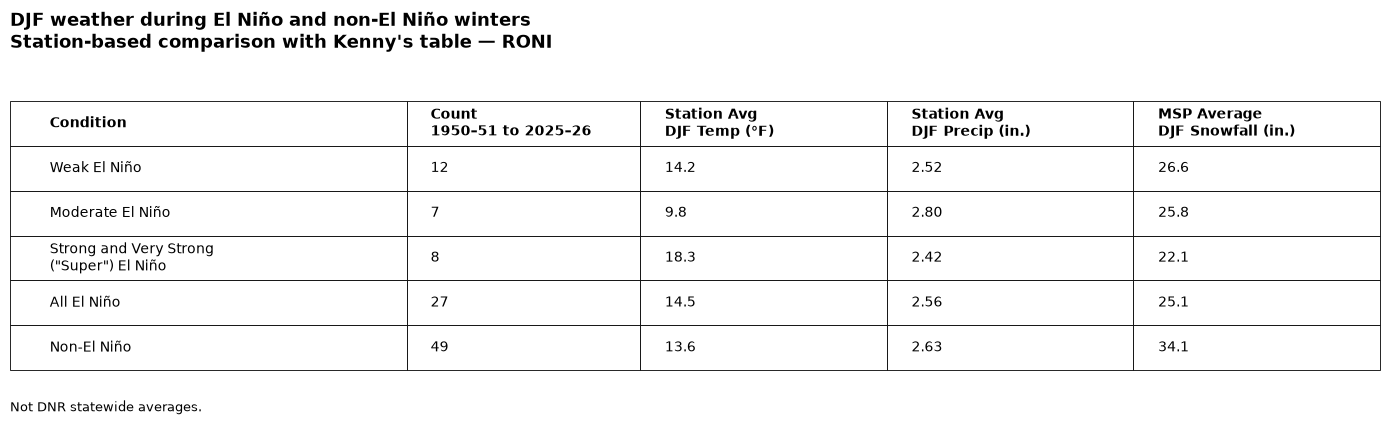

,Condition,Our count,Kenny count,Difference
0,Weak El Niño,12,8,4
1,Moderate El Niño,7,10,-3
2,"Strong and Very Strong (""Super"") El Niño",8,9,-1
3,All El Niño,27,27,0
4,Non-El Niño,49,49,0


,Condition,Classified winters,Temp valid winters,Precip valid winters,Snow valid winters
0,Weak El Niño,12,12,12,12
1,Moderate El Niño,7,4,6,7
2,"Strong and Very Strong (""Super"") El Niño",8,6,7,8
3,All El Niño,27,22,25,27
4,Non-El Niño,49,42,46,49


In [52]:
# DJF analysis using our stations in Kenny's table layout
def kenny_table(
    station_seasons, index_seasons, *, enabled=False,
    output_dir=Path("../outputs/kenny_table"),
):
    if not enabled:
        return None

    #match the reference period: winter 1950-51 through 2025-26
    winters = index_seasons.loc[
        index_seasons["season"].eq("DJF")
        & index_seasons["season_year"].between(1951, 2026),
        ["season_year", "RONI_episode", "RONI_season_strength"],
    ].copy()
    if (
        winters["season_year"].duplicated().any()
        or set(winters["season_year"]) != set(range(1951, 2027))
        or winters["RONI_episode"].isna().any()
    ):
        raise ValueError("The benchmark requires 76 uniquely classified winters.")

    #use DJF strength, consistent with the main seasonal analysis
    strong = 'Strong and Very Strong ("Super") El Niño'
    strength_labels = {
        "Weak El Niño": "Weak El Niño",
        "Moderate El Niño": "Moderate El Niño",
        "Strong El Niño": strong,
        "Very Strong El Niño": strong,
    }
    warm = winters["RONI_episode"].astype("boolean")
    winters["Condition"] = "Non-El Niño"
    winters.loc[warm, "Condition"] = (
        winters.loc[warm, "RONI_season_strength"].map(strength_labels)
    )
    if winters["Condition"].isna().any():
        raise ValueError("A confirmed El Niño winter has no recognized strength.")

    #use accepted DJF weather values; require all nine stations for regional means
    weather = station_seasons.loc[
        station_seasons["season"].eq("DJF")
        & station_seasons["season_year"].between(1951, 2026),
        ["station", "season_year", "temp_f", "precip_in", "snow_in"],
    ].copy()
    if weather.duplicated(["station", "season_year"]).any():
        raise ValueError("The benchmark contains duplicate station-winters.")
    regional = weather.groupby("season_year").agg(
        station_n=("station", "nunique"),
        temp_n=("temp_f", "count"), temp_f=("temp_f", "mean"),
        precip_n=("precip_in", "count"), precip_in=("precip_in", "mean"),
    ).reset_index()
    if len(regional) != 76 or regional["station_n"].ne(9).any():
        raise ValueError("Each benchmark winter requires nine primary-station rows.")
    for metric in ["temp", "precip"]:
        value_column = "temp_f" if metric == "temp" else "precip_in"
        regional[value_column] = regional[value_column].where(
            regional[f"{metric}_n"].eq(9)
        )

    #snowfall comes from MSP, including the approved donor replacements
    msp = weather.loc[
        weather["station"].eq("USW00014922"), ["season_year", "snow_in"]
    ]
    winters = winters.merge(
        regional, on="season_year", how="left", validate="one_to_one"
    ).merge(msp, on="season_year", how="left", validate="one_to_one")

    #calculate combined rows from winter records, not averages of category means
    groups = [
        ("Weak El Niño", winters["Condition"].eq("Weak El Niño")),
        ("Moderate El Niño", winters["Condition"].eq("Moderate El Niño")),
        (strong, winters["Condition"].eq(strong)),
        ("All El Niño", winters["Condition"].ne("Non-El Niño")),
        ("Non-El Niño", winters["Condition"].eq("Non-El Niño")),
    ]
    rows, coverage_rows = [], []
    for condition, selected in groups:
        group = winters.loc[selected]
        rows.append([
            condition, len(group), group["temp_f"].mean(),
            group["precip_in"].mean(), group["snow_in"].mean(),
        ])
        coverage_rows.append([
            condition, len(group), group["temp_f"].count(),
            group["precip_in"].count(), group["snow_in"].count(),
        ])

    columns = [
        "Condition", "Count", "Station winter temp (F)",
        "Nine Station winter precip (in.)", "MSP DJF snowfall (in.)",
    ]
    table = pd.DataFrame(rows, columns=columns)
    coverage = pd.DataFrame(coverage_rows, columns=[
        "Condition", "Classified winters", "Temp valid winters",
        "Precip valid winters", "Snow valid winters",
    ])

    #show current counts beside the published reference counts
    count_check = table[["Condition", "Count"]].rename(columns={"Count": "Our count"})
    count_check["Kenny count"] = [8, 10, 9, 27, 49]
    count_check["Difference"] = count_check["Our count"] - count_check["Kenny count"]

    #white background and black grid, with the same five-column row layout
    cells = []
    for row in table.itertuples(index=False, name=None):
        label = row[0].replace(strong, 'Strong and Very Strong\n("Super") El Niño')
        cells.append([label, str(row[1])] + [
            f"{value:.{places}f}" if pd.notna(value) else "—"
            for value, places in zip(row[2:], [1, 2, 1])
        ])
    headers = [
        "Condition", "Count\n1950–51 to 2025–26",
        "Station Avg\nDJF Temp (°F)",
        "Station Avg\nDJF Precip (in.)",
        "MSP Average\nDJF Snowfall (in.)",
    ]
    fig, ax = plt.subplots(figsize=(14, 4.5), facecolor="white")
    ax.set_axis_off()
    artist = ax.table(
        cellText=cells, colLabels=headers, cellLoc="left", colLoc="left",
        colWidths=[0.29, 0.17, 0.18, 0.18, 0.18], bbox=[0, 0.16, 1, 0.72],
    )
    artist.auto_set_font_size(False)
    artist.set_fontsize(10)
    for (row, column), cell in artist.get_celld().items():
        cell.set_facecolor("white")
        cell.set_edgecolor("black")
        cell.set_linewidth(0.6)
        cell.set_text_props(color="black", fontweight="bold" if row == 0 else "normal")
    ax.set_title(
        "DJF weather during El Niño and non-El Niño winters\n"
        "Station-based comparison with Kenny's table — RONI",
        loc="left", color="black", fontsize=13, fontweight="bold",
    )
    ax.text(
        0, 0.05,
        "Not DNR statewide averages. ",
        transform=ax.transAxes, color="black", fontsize=9,
    )
    fig.tight_layout()

    #save stable filenames only when this optional function is enabled
    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)
        table.to_csv(output_dir / "kenny_station_comparison.csv", index=False)
        coverage.to_csv(output_dir / "kenny_station_comparison_coverage.csv", index=False)
        count_check.to_csv(output_dir / "kenny_count_check.csv", index=False)
        fig.savefig(output_dir / "kenny_station_comparison.png", dpi=200, facecolor="white")
    plt.show()
    plt.close(fig)
    display(count_check)
    display(coverage)
    return {
        "table": table, "count_check": count_check,
        "coverage": coverage, "winters": winters,
    }

#toggle the optional Kenny comparison
kenny_result = kenny_table(
    station_season_table,
    seasonal_index_table,
    enabled=True,
)

In [59]:
#here the primary obs + index table is focused on djf 
#and summarized in text
#and should be cross referenced with outside data by the user

#first pull out djf obs
raw_table_df['time']=pd.to_datetime(raw_table_df['time'])
djf_obs = raw_table_df[raw_table_df['time'].dt.month.isin([12, 1, 2])].copy()


columns = [
    'winter_year',
    'ONI_episode',
    'ONI_episode_strength',
    'RONI_episode',
    'RONI_episode_strength'
]

winter_table = (
    djf_obs.loc[djf_obs['time'].dt.month == 1, columns]
    .drop_duplicates(subset='winter_year')
    .set_index('winter_year')
    .sort_index()
)
winter_table = winter_table.loc[1950:2026].copy() #this will produce the 'Kenny Table'

# Retain winters with no January observations as unclassified.
all_winters = pd.Index(
    sorted(djf_obs['winter_year'].dropna().unique()),
    name='winter_year'
)

winter_table = winter_table.reindex(all_winters)

for index in ['ONI', 'RONI']:
    status = winter_table[f'{index}_episode'].astype('boolean')

    yes = status.eq(True).fillna(False)
    no = status.eq(False).fillna(False)
    unknown = status.isna()

    label_column = f'{index}_winter_class'
    winter_table[label_column] = 'Unclassified'

    winter_table.loc[yes, label_column] = winter_table.loc[
        yes, f'{index}_episode_strength'
    ]
    winter_table.loc[no, label_column] = 'No El Niño episode at DJF'

    known_years = winter_table.index[status.notna()]

    if len(known_years) > 0:
        start_year = known_years.min()
        end_year = known_years.max()

        print(
            'According to the', index, 'there were',
            int(yes.sum()),
            'winters coinciding with El Niño conditions in the Pacific between',
            start_year, 'and', end_year
        )

        print(
            'According to the', index, 'there were',
            int(no.sum()),
            'winters not coinciding with El Niño conditions in the Pacific between',
            start_year, 'and', end_year
        )
    else:
        print('No winters could be classified using the', index)

    print('Winters with unknown episode status:', int(unknown.sum()))
    print()

#uncomment to look at the table
display(winter_table)

#these values match both NOAA records and Brian Mcnoldy approximatly (+/- 1 episode)
#check project log for disagreement, spoiler its from rounding
#when in 'kenny table mode' it says 46 unclassified its referring to years before 1950 that arent becing counted

According to the ONI there were 25 winters coinciding with El Niño conditions in the Pacific between 1950 and 2026
According to the ONI there were 52 winters not coinciding with El Niño conditions in the Pacific between 1950 and 2026
Winters with unknown episode status: 46

According to the RONI there were 27 winters coinciding with El Niño conditions in the Pacific between 1950 and 2026
According to the RONI there were 50 winters not coinciding with El Niño conditions in the Pacific between 1950 and 2026
Winters with unknown episode status: 46



,ONI_episode,ONI_episode_strength,RONI_episode,RONI_episode_strength,ONI_winter_class,RONI_winter_class
winter_year,,,,,,
1892,<NA>,NaN,<NA>,NaN,Unclassified,Unclassified
1893,<NA>,NaN,<NA>,NaN,Unclassified,Unclassified
1894,<NA>,NaN,<NA>,NaN,Unclassified,Unclassified
1905,<NA>,NaN,<NA>,NaN,Unclassified,Unclassified
1906,<NA>,NaN,<NA>,NaN,Unclassified,Unclassified
...,...,...,...,...,...,...
2022,False,NaN,False,NaN,No El Niño episode at DJF,No El Niño episode at DJF
2023,False,NaN,False,NaN,No El Niño episode at DJF,No El Niño episode at DJF
2024,True,Strong El Niño,True,Moderate El Niño,Strong El Niño,Moderate El Niño


## Analysis
This part:
- converts units to imperial 
- averages station vars over winters  
- excludes measurments with quality flags or missing values
    - the counts of djfs do not follow this rule
- makes all final calulations that go into data viz


In [54]:
#copy the primary obs and index table
mnwx=djf_obs.copy()


#check for quality flags
for variable in ['PRCP', 'SNOW', 'TMAX', 'TMIN']:
    mnwx[variable]=mnwx[variable].where(
        mnwx[f'{variable}_q'].eq(False)
    )


#convert precip and snowfall from mm to in 
mnwx['precip_in']=mnwx['PRCP']/25.4
mnwx['snow_in']=mnwx['SNOW']/25.4


#calculate mean temperature converting C to F
#if tmax or tmin missing no result
mnwx['temp_f']=(
    (mnwx['TMAX']+mnwx['TMIN'])/2
)*9/5+32


#calculate measurments per stations per winter
station_winters=mnwx.groupby(
    ['station', 'winter_year']).agg(
        precip_in=('precip_in', lambda values: values.sum(min_count=1)),
        snow_in=('snow_in', lambda values: values.sum(min_count=1)),
        temp_f=('temp_f','mean'),
        precip_days=('precip_in', 'count'),
        snow_days= ('snow_in','count'),
        temp_days=('temp_f', 'count'),
                                    )


#account for leap years
years=station_winters.index.get_level_values('winter_year')
expected_days=90+pd.to_datetime(
    years.astype(str)+'-01-01'
).is_leap_year.astype(int)

#record missing and quality flagged measurments
for measurment, count_column, missing_column in [
    ('precip_in', 'precip_days', 'precip_missing_days'),
    ('snow_in', 'snow_days', 'snow_missing_days'),
    ('temp_f', 'temp_days', 'temp_missing_days')
]:
    station_winters[missing_column]=(
        expected_days-station_winters[count_column]
    )

    station_winters[measurment]=station_winters[measurment].where(
        station_winters[count_column].eq(expected_days) #fake error
    )

#add index winter classifications
station_winters=station_winters.join(
    winter_table[['ONI_winter_class', 'RONI_winter_class']],
    on= 'winter_year',
    how='inner',
    validate='many_to_one'
)

classification= [
    'Very Strong El Niño',
    'Strong El Niño',
    'Moderate El Niño',
    'Weak El Niño',
    'No El Niño episode at DJF'
]

#hold calc results
summaries={}

for index in ['ONI', 'RONI']:
    classification_column=f'{index}_winter_class'

    #avg winters per stations
    station_averages=station_winters.groupby(
        ['station', classification_column]
    )[['precip_in','snow_in', 'temp_f']].mean()

    #average the station avaerages(equal weight)
    summary=(
        station_averages.groupby(level=classification_column).mean().reindex(classification)
    )
    #count winters from rows
    summary['winter_count']=(
        winter_table[classification_column].value_counts().reindex(classification, fill_value=0)
    )

    summaries[index]=summary


#final aggregated table

roni_summary = summaries['RONI']
oni_summary = summaries['ONI']

#uncomment to see new tables
display(oni_summary)
display(roni_summary)


,precip_in,snow_in,temp_f,winter_count
ONI_winter_class,,,,
Very Strong El Niño,NaN,NaN,NaN,0
Strong El Niño,2.446496,23.825293,18.008904,17
Moderate El Niño,2.738944,32.125107,14.244716,12
Weak El Niño,2.484565,27.936716,13.345572,8
No El Niño episode at DJF,2.589882,31.202066,13.366276,85


,precip_in,snow_in,temp_f,winter_count
RONI_winter_class,,,,
Very Strong El Niño,2.712348,24.869703,17.996679,7
Strong El Niño,2.087321,24.311502,16.525681,14
Moderate El Niño,2.427706,27.189415,14.067395,11
Weak El Niño,2.704061,30.042259,13.821896,8
No El Niño episode at DJF,2.607669,31.368235,13.503341,82


In [55]:
#here the djf primary obs and index table copy data is initialized for placement into a visualization table

#the followed are assigned variables:
    #average seasonal precip in inches,
    #sum seasonal snowfall in inches, note winter is summed within each winter then averaged across nino strength category
    #average seasonal temperature,
    #sum of year's el nino varities (strong, very strong , etc)
#   sum of year's no el nino conditions 


#----------- roni calcs ----------

#very strong el nino conditions
avg_djf_vsen_precip_roni= roni_summary.loc['Very Strong El Niño', 'precip_in']
djf_vsen_snowfall_total_roni= roni_summary.loc['Very Strong El Niño', 'snow_in']
avg_djf_vsen_temp_roni= roni_summary.loc['Very Strong El Niño', 'temp_f']
ndjf_vsen_roni= int(roni_summary.loc['Very Strong El Niño','winter_count'])#number of djf with very strong el nino

#strong el nino conditions
avg_djf_sen_precip_roni= roni_summary.loc['Strong El Niño', 'precip_in']
djf_sen_snowfall_total_roni= roni_summary.loc['Strong El Niño', 'snow_in']
avg_djf_sen_temp_roni= roni_summary.loc['Strong El Niño', 'temp_f']
ndjf_sen_roni= int(roni_summary.loc['Strong El Niño','winter_count']) #number of djf with strong el nino

#moderate el nino conditions
avg_djf_men_precip_roni= roni_summary.loc['Moderate El Niño','precip_in']
djf_men_snowfall_total_roni= roni_summary.loc['Moderate El Niño','snow_in']
avg_djf_men_temp_roni= roni_summary.loc['Moderate El Niño','temp_f']
ndjf_men_roni= int(roni_summary.loc['Moderate El Niño','winter_count'])#number of djf with moderate el nino

#weak el nino conditions
avg_djf_wen_precip_roni= roni_summary.loc['Weak El Niño','precip_in']
djf_wen_snowfall_total_roni= roni_summary.loc['Weak El Niño','snow_in']
avg_djf_wen_temp_roni= roni_summary.loc['Weak El Niño','temp_f']
ndjf_wen_roni= int(roni_summary.loc['Weak El Niño','winter_count'])#number of djf with weak el nino

#non el nino conditions
avg_djf_nenso_precip_roni= roni_summary.loc['No El Niño episode at DJF','precip_in']
djf_nenso_snowfall_total_roni= roni_summary.loc['No El Niño episode at DJF','snow_in']
avg_djf_nenso_temp_roni= roni_summary.loc['No El Niño episode at DJF','temp_f']
ndjf_nenso_roni= int(roni_summary.loc['No El Niño episode at DJF','winter_count']) #number of djf with no el nino


#---------- oni calcs ----------


#strong el nino conditions
avg_djf_sen_precip_oni= oni_summary.loc['Strong El Niño', 'precip_in']
djf_sen_snowfall_total_oni= oni_summary.loc['Strong El Niño', 'snow_in']
avg_djf_sen_temp_oni= oni_summary.loc['Strong El Niño', 'temp_f']
ndjf_sen_oni= int(oni_summary.loc['Strong El Niño','winter_count'])#number of djf with strong el nino

#moderate el nino conditions
avg_djf_men_precip_oni= oni_summary.loc['Moderate El Niño','precip_in']
djf_men_snowfall_total_oni= oni_summary.loc['Moderate El Niño','snow_in']
avg_djf_men_temp_oni= oni_summary.loc['Moderate El Niño','temp_f']
ndjf_men_oni= int(oni_summary.loc['Moderate El Niño','winter_count'])#number of djf with moderate el nino

#weak el nino conditions
avg_djf_wen_precip_oni= oni_summary.loc['Weak El Niño','precip_in']
djf_wen_snowfall_total_oni= oni_summary.loc['Weak El Niño','snow_in']
avg_djf_wen_temp_oni= oni_summary.loc['Weak El Niño','temp_f']
ndjf_wen_oni= int(oni_summary.loc['Weak El Niño','winter_count'])#number of djf with weak el nino

#non el nino conditions
avg_djf_nenso_precip_oni= oni_summary.loc['No El Niño episode at DJF','precip_in']
djf_nenso_snowfall_total_oni= oni_summary.loc['No El Niño episode at DJF','snow_in']
avg_djf_nenso_temp_oni= oni_summary.loc['No El Niño episode at DJF','temp_f']
ndjf_nenso_oni= int(oni_summary.loc['No El Niño episode at DJF','winter_count'])#number of djf with no el nino


## Vizualization

Index([4, 3, 2, 1, 0], dtype='int64', name='RONI_winter_class')
['Very Strong El Niño', 'Strong El Niño', 'Moderate El Niño', 'Weak El Niño', 'No El Niño episode at DJF']
[[4 4 4 4]
 [3 3 3 3]
 [2 2 2 2]
 [1 1 1 1]
 [0 0 0 0]]


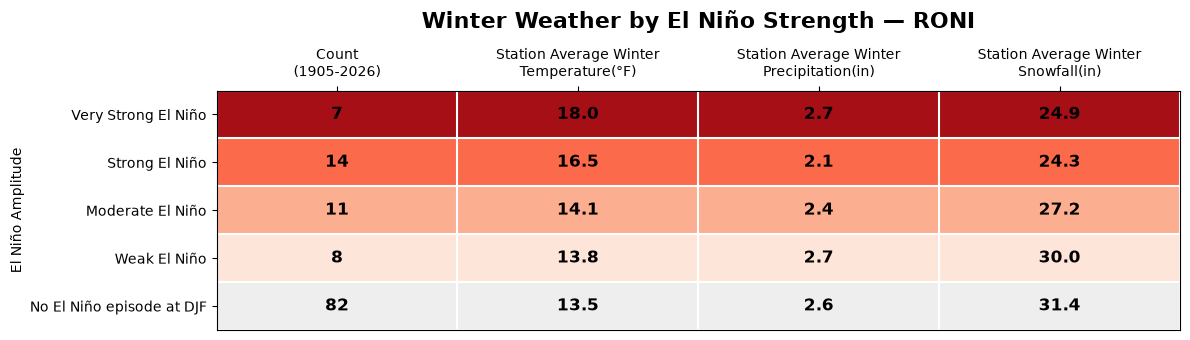

In [56]:
#form data viz
#going to resuse the charts from the WASP

#lists that can be used for charts
roni_plot_table=roni_summary[
    ['winter_count','temp_f','precip_in','snow_in']
]
titles=['Count\n(1905-2026)','Station Average Winter\nTemperature(°F)','Station Average Winter\nPrecipitation(in)','Station Average Winter\nSnowfall(in)']
amplitudes={
    'Very Strong El Niño':4,
    'Strong El Niño':3,
    'Moderate El Niño':2,
    'Weak El Niño':1,
    'No El Niño episode at DJF':0
}

#makes sure rows is conected to the amplitudes
rows=roni_summary.index.map(amplitudes)
print(rows)
print(roni_summary.index.tolist())

#establishes the color scheme layout
roni_colors=np.repeat(
    np.array(rows)[:, None],
    roni_summary.shape[1], #.shape returns (nrows, ncolumns)
    axis=1
)
print(roni_colors) #progress check

#establishes the color scheme colors
amp_colors=ListedColormap([
    '#eeeeee', #0
    '#fee5d9', #1
    '#fcae91', #2
    '#fb6a4a', #3
    '#a50f15'  #4
])

fig, ax=plt.subplots(figsize=(12,3.5))

ax.imshow(
    roni_colors,
    cmap=amp_colors,
    vmin=-0.5,
    vmax=4.5,
    aspect='auto'
)



#label each column
ax.set_xticks(range(roni_summary.shape[1]))
ax.set_xticklabels(titles)
ax.tick_params( #puts labels above tables
    top=True,
    labeltop=True,
    bottom=False,
    labelbottom=False
)

#label each row and the y in general
ax.set_ylabel('El Niño Amplitude')
ax.set_yticks(range(roni_summary.shape[0]))
ax.set_yticklabels(roni_summary.index)



#add the numbers
for row in range(roni_plot_table.shape[0]):
    for col in range(roni_plot_table.shape[1]):
        value = roni_plot_table.iloc[row, col]

        # Show missing measurements as a dash.
        if pd.isna(value):
            label = '—'
        elif col == 0:
            label = f'{value:.0f}'  # Winter count: no decimals
        else:
            label = f'{value:.1f}'  # Weather measurements: one decimal

        ax.text(
                col, row, label,
                ha='center',
                va='center',
                fontsize=12,
                fontweight='bold',
                color='black'
        )

#grid the chart 
# Cell centers are 0, 1, 2...; edges are -0.5, 0.5, 1.5...
ax.set_xticks(
    np.arange(roni_plot_table.shape[1] + 1) - 0.5,
    minor=True
)
ax.set_yticks(
    np.arange(roni_plot_table.shape[0] + 1) - 0.5,
    minor=True
)

ax.grid(which='minor', color='white', linewidth=1.5)
ax.tick_params(which='minor', bottom=False, top=False,
               left=False, right=False)

# title the chart
ax.set_title(
    'Winter Weather by El Niño Strength — RONI',
    fontsize=16,
    fontweight='bold',
    pad=45
)
plt.tight_layout()
plt.show() #progress check